In [1]:
"""Develop interactive and responsive data visualizations and dashboards in Streamlit using custom components and integrations with libraries like Plotly, Vega, and Altair to enhance user engagement and insights discovery."""

'Develop interactive and responsive data visualizations and dashboards in Streamlit using custom components and integrations with libraries like Plotly, Vega, and Altair to enhance user engagement and insights discovery.'

In [2]:
# load dataset and compute sales performance indicators
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import altair as alt

df = pd.read_csv("global_pharmacy_sales_data.csv")
df['revenue'] = df['units_sold'] * df['unit_price']
df['date'] = pd.to_datetime(df['date'])
df['year_month'] = df['date'].dt.to_period('M').astype(str)
print("dataset dimensions:", df.shape)
print(df[['date', 'year_month', 'region', 'category', 'medicine', 'units_sold', 'revenue']].head(3))


dataset dimensions: (177990, 16)
        date year_month       region category    medicine  units_sold  \
0 2025-10-12    2025-10  Middle East  Chronic  Amlodipine         328   
1 2020-09-15    2020-09   South Asia  Chronic  Amlodipine         371   
2 2020-02-26    2020-02  Middle East  Vitamin   Vitamin C         948   

    revenue  
0  14884.64  
1  28006.79  
2  21339.48  


In [3]:
# aggregate multi dimensional metrics for category and regional trends
region_summary = df.groupby('region').agg({'units_sold': 'sum', 'revenue': 'sum'}).reset_index()
category_summary = df.groupby('category').agg({'units_sold': 'sum', 'revenue': 'sum'}).reset_index()
monthly_summary = df.groupby('year_month')['revenue'].sum().reset_index()
print("regional summary:")
print(region_summary)
print("category summary:")
print(category_summary)


regional summary:
          region  units_sold       revenue
0         Africa     9879220  5.204328e+08
1      East Asia    10019811  5.292539e+08
2         Europe     9931014  5.241345e+08
3    Middle East    10001814  5.239983e+08
4  North America     9931812  5.220569e+08
5        Oceania    10001961  5.235241e+08
6  South America     9985310  5.267808e+08
7     South Asia     9973244  5.206311e+08
category summary:
      category  units_sold       revenue
0   Antibiotic    15927524  8.394242e+08
1  Antipyretic    16005035  8.429341e+08
2      Chronic    15935086  8.343651e+08
3   Cough_Cold    15895930  8.395075e+08
4      Vitamin    15960611  8.345813e+08


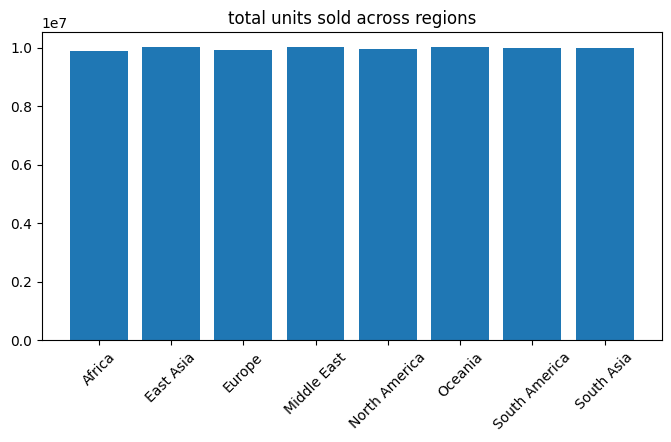

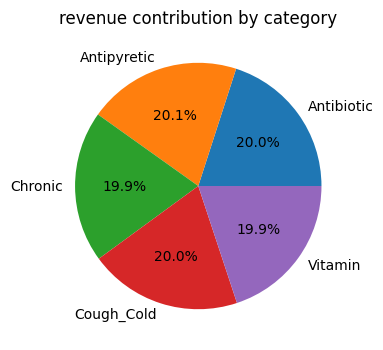

In [4]:
# plot basic sales distributions with easy matplotlib charts
plt.figure(figsize=(8, 4))
plt.bar(region_summary['region'], region_summary['units_sold'])
plt.title("total units sold across regions")
plt.xticks(rotation=45)
plt.show()

plt.figure(figsize=(6, 4))
plt.pie(category_summary['revenue'], labels=category_summary['category'], autopct='%1.1f%%')
plt.title("revenue contribution by category")
plt.show()


In [5]:
# generate interactive multi chart visual insights with plotly and altair
sample_df = df.sample(800, random_state=42)

fig_trend = px.line(
    monthly_summary.head(24),
    x='year_month',
    y='revenue',
    title="monthly revenue progression over time"
)

fig_scatter = px.scatter(
    sample_df,
    x="stock_level",
    y="units_sold",
    color="category",
    size="unit_price",
    title="stock level vs units sold with category segmentation"
)

chart_altair = alt.Chart(sample_df).mark_circle(size=70).encode(
    x='unit_price:Q',
    y='units_sold:Q',
    color='category:N',
    tooltip=['medicine:N', 'unit_price:Q', 'units_sold:Q', 'region:N']
).interactive().properties(title="price to demand correlation analysis")

print("interactive plotly and altair figures initialized")


interactive plotly and altair figures initialized


In [6]:
# build feature rich interactive streamlit dashboard with plotly and altair
dashboard_code = '''import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px
import altair as alt

st.set_page_config(page_title="Pharmacy Visual Analytics Dashboard", layout="wide")
st.title("Pharmacy Global Sales & Insights Dashboard")

@st.cache_data
def load_data():
    data = pd.read_csv("global_pharmacy_sales_data.csv")
    data['date'] = pd.to_datetime(data['date'])
    data['revenue'] = data['units_sold'] * data['unit_price']
    data['year_month'] = data['date'].dt.to_period('M').astype(str)
    return data

df = load_data()

st.sidebar.header("Interactive Dashboard Filters")
min_year, max_year = int(df['year'].min()), int(df['year'].max())
selected_years = st.sidebar.slider("Select Year Range", min_year, max_year, (min_year, max_year))

all_regions = list(df['region'].unique())
selected_regions = st.sidebar.multiselect("Select Regions", options=all_regions, default=all_regions[:4])

all_categories = ["All"] + list(df['category'].unique())
selected_category = st.sidebar.selectbox("Filter by Category", options=all_categories)

all_age_groups = ["All"] + list(df['age_group'].unique())
selected_age_group = st.sidebar.selectbox("Filter by Age Group", options=all_age_groups)

filtered_df = df[(df['year'] >= selected_years[0]) & (df['year'] <= selected_years[1])]
if selected_regions:
    filtered_df = filtered_df[filtered_df['region'].isin(selected_regions)]
if selected_category != "All":
    filtered_df = filtered_df[filtered_df['category'] == selected_category]
if selected_age_group != "All":
    filtered_df = filtered_df[filtered_df['age_group'] == selected_age_group]

k1, k2, k3, k4, k5 = st.columns(5)
k1.metric("Filtered Records", f"{len(filtered_df):,}")
k2.metric("Total Revenue", f"${filtered_df['revenue'].sum():,.2f}")
k3.metric("Total Units Sold", f"{filtered_df['units_sold'].sum():,}")
k4.metric("Avg Unit Price", f"${filtered_df['unit_price'].mean():.2f}")
k5.metric("Avg Stock Level", f"{int(filtered_df['stock_level'].mean()):,}")

tab1, tab2, tab3, tab4 = st.tabs([
    "Executive Overview",
    "Product & Regional Breakdown",
    "Pricing & Inventory Insights",
    "Data Explorer & Export"
])

with tab1:
    st.subheader("Monthly Revenue Trends Over Time (Plotly)")
    monthly_trend = filtered_df.groupby('year_month')['revenue'].sum().reset_index()
    fig_line = px.line(monthly_trend, x='year_month', y='revenue', title="Monthly Revenue Trajectory", markers=True)
    st.plotly_chart(fig_line, use_container_width=True)

with tab2:
    st.subheader("Regional & Category Distribution (Plotly)")
    col_a, col_b = st.columns(2)
    with col_a:
        reg_summary = filtered_df.groupby('region')['units_sold'].sum().reset_index()
        fig_bar = px.bar(reg_summary, x='region', y='units_sold', color='region', title="Total Units Sold by Region")
        st.plotly_chart(fig_bar, use_container_width=True)
    with col_b:
        cat_summary = filtered_df.groupby('category')['revenue'].sum().reset_index()
        fig_pie = px.pie(cat_summary, values='revenue', names='category', title="Revenue Share by Category")
        st.plotly_chart(fig_pie, use_container_width=True)

with tab3:
    st.subheader("Interactive Pricing vs Demand (Altair)")
    sample_size = min(1500, len(filtered_df))
    chart_sample = filtered_df.sample(sample_size, random_state=42)
    altair_scatter = alt.Chart(chart_sample).mark_circle(size=70).encode(
        x='unit_price:Q',
        y='units_sold:Q',
        color='category:N',
        tooltip=['medicine:N', 'unit_price:Q', 'units_sold:Q', 'region:N', 'age_group:N']
    ).interactive().properties(title="Unit Price vs Units Sold Dynamics", height=400)
    st.altair_chart(altair_scatter, use_container_width=True)
    
    st.subheader("Stock Level vs Demand by Category (Plotly)")
    fig_scatter = px.scatter(
        chart_sample,
        x='stock_level',
        y='units_sold',
        color='category',
        size='unit_price',
        hover_data=['medicine', 'region'],
        title="Stock Level vs Units Sold (Size = Price)"
    )
    st.plotly_chart(fig_scatter, use_container_width=True)

with tab4:
    st.subheader("Filtered Dataset Preview & Data Export")
    st.dataframe(filtered_df.head(25), use_container_width=True)
    csv_download = filtered_df.to_csv(index=False).encode('utf-8')
    st.download_button("Download Filtered Data (CSV)", csv_download, "pharmacy_filtered_data.csv", "text/csv")
'''

with open("app.py", "w") as f:
    f.write(dashboard_code.strip())
print("interactive dashboard app.py created successfully")


interactive dashboard app.py created successfully


In [7]:
# display instructions to launch interactive visual dashboard
print("run 'streamlit run app.py' in terminal to launch interactive dashboard")


run 'streamlit run app.py' in terminal to launch interactive dashboard
